# Exploratory Data Analysis (EDA) Report

## Week 2 — Day 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv(
    r"C:\Users\KUMUDHA\Downloads\Sample - Superstore.csv",
    encoding="cp1252"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Dataset information
print("\nDataset information:")
df.info()

Number of rows: 9994
Number of columns: 21

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing values:


,Missing Count
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0



Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales      

In [3]:
# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# Convert date columns
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

print("Updated column names:")
print(df.columns.tolist())

print("\nUpdated date types:")
print(df[["order_date", "ship_date"]].dtypes)

Updated column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Updated date types:
order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object


In [4]:
# Identify numeric columns
numeric_df = df.select_dtypes(include="number")

# Generate summary statistics
summary_stats = numeric_df.describe().T

# Add additional statistics
summary_stats["median"] = numeric_df.median()
summary_stats["missing_values"] = numeric_df.isnull().sum()
summary_stats["unique_values"] = numeric_df.nunique()

display(summary_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,missing_values,unique_values
row_id,9994.0,4997.50,2885.16,1.00,2499.25,4997.50,7495.75,9994.00,4997.50,0,9994
postal_code,9994.0,55190.38,32063.69,1040.00,23223.00,56430.50,90008.00,99301.00,56430.50,0,631
sales,9994.0,229.86,623.25,0.44,17.28,54.49,209.94,22638.48,54.49,0,5825
quantity,9994.0,3.79,2.23,1.00,2.00,3.00,5.00,14.00,3.00,0,14
discount,9994.0,0.16,0.21,0.00,0.00,0.20,0.20,0.80,0.20,0,12
profit,9994.0,28.66,234.26,-6599.98,1.73,8.67,29.36,8399.98,8.67,0,7287


Numeric columns: ['row_id', 'postal_code', 'sales', 'quantity', 'discount', 'profit']


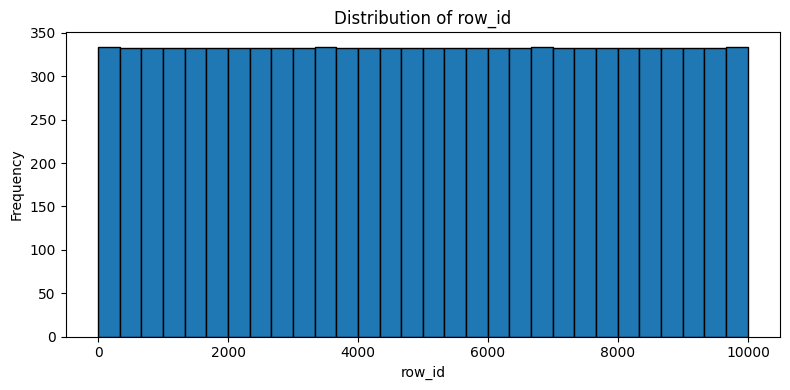

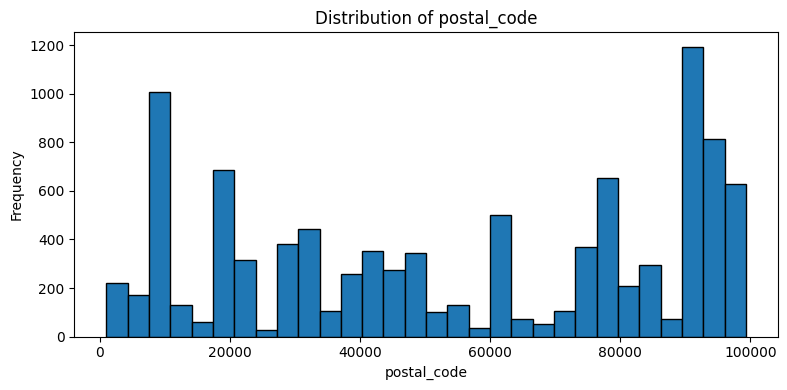

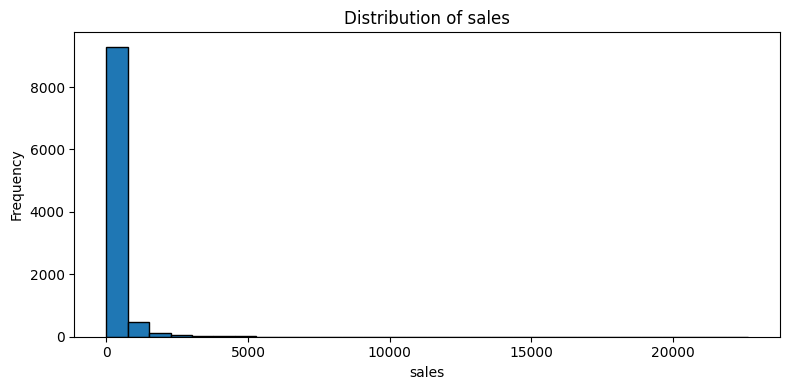

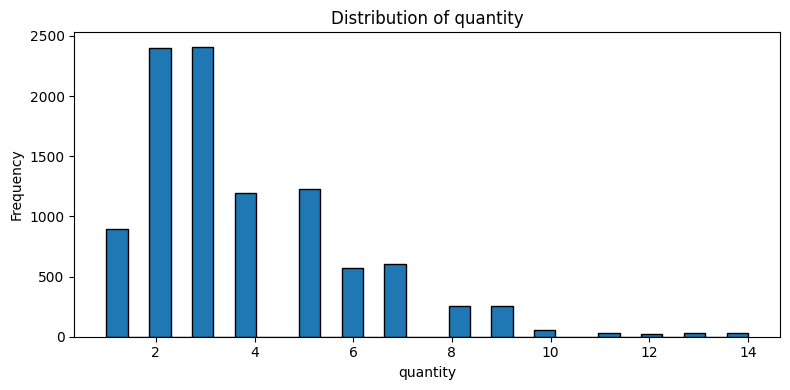

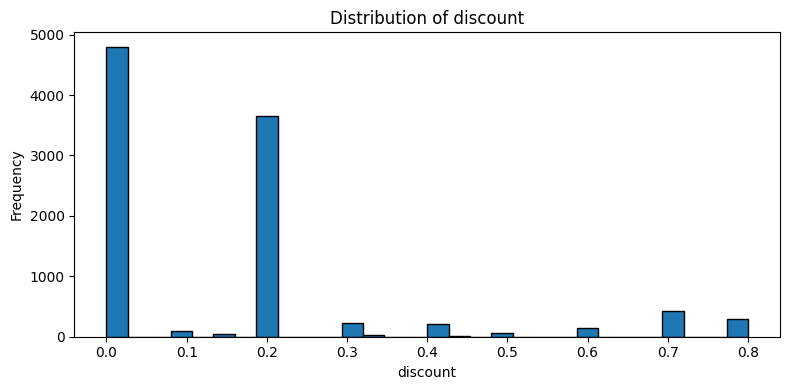

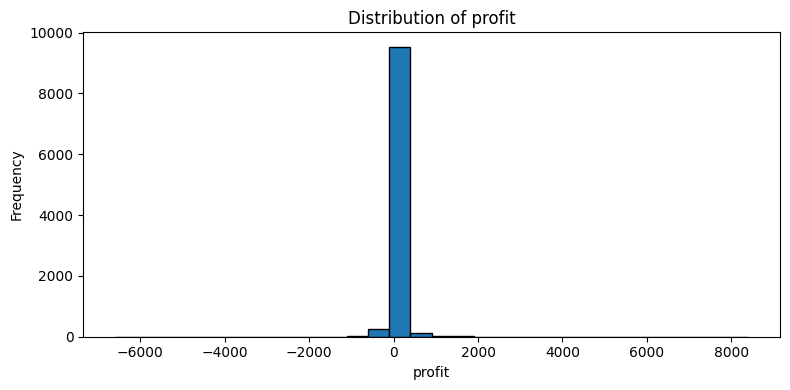

In [5]:
# Select numerical columns
numeric_columns = df.select_dtypes(include="number").columns

print("Numeric columns:", numeric_columns.tolist())

# Plot distributions
for column in numeric_columns:
    plt.figure(figsize=(8, 4))

    plt.hist(
        df[column].dropna(),
        bins=30,
        edgecolor="black"
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [6]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\KUMUDHA\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


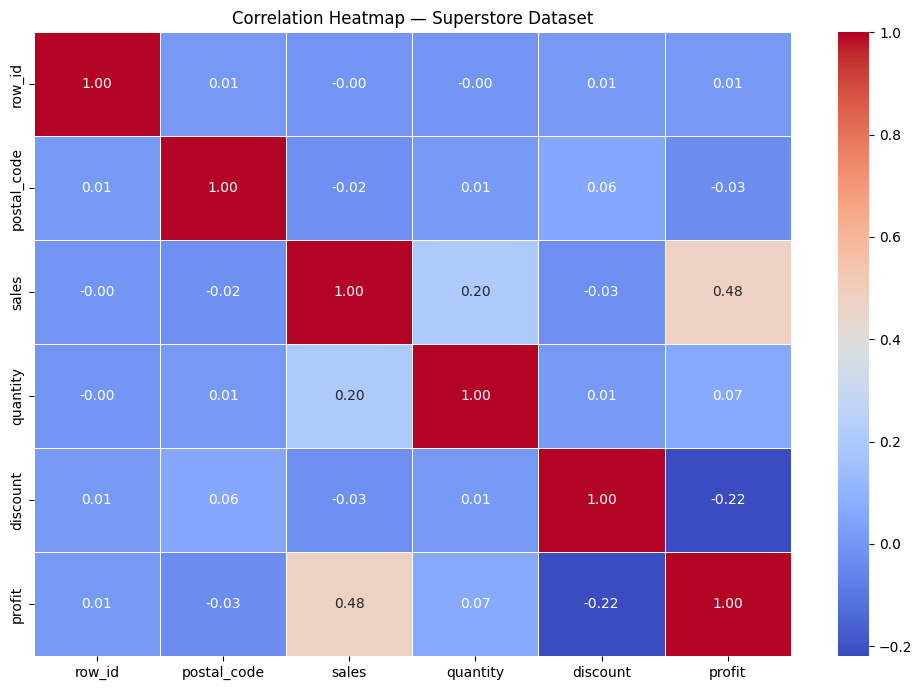

In [7]:
import seaborn as sns

# Select numeric columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap — Superstore Dataset")
plt.tight_layout()
plt.show()

In [8]:
# Analyse outliers in key business metrics
outlier_columns = ["sales", "profit", "quantity", "discount"]

outlier_results = []

for column in outlier_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,sales,-271.71,498.93,1167,11.68
1,profit,-39.72,70.82,1881,18.82
2,quantity,-2.50,9.50,170,1.70
3,discount,-0.30,0.50,856,8.57


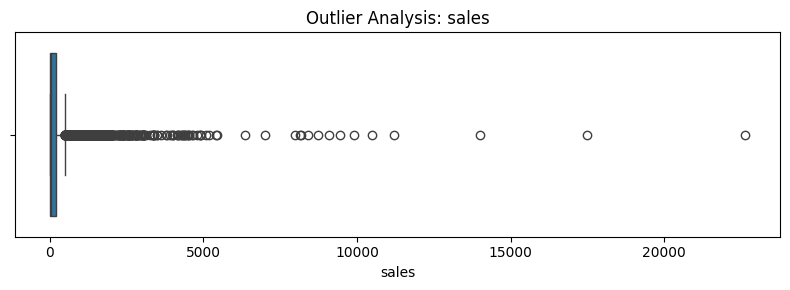

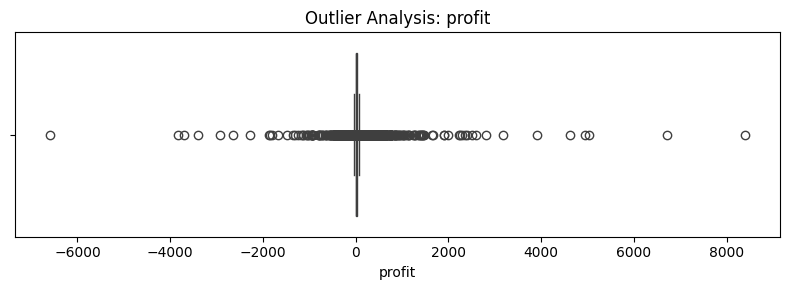

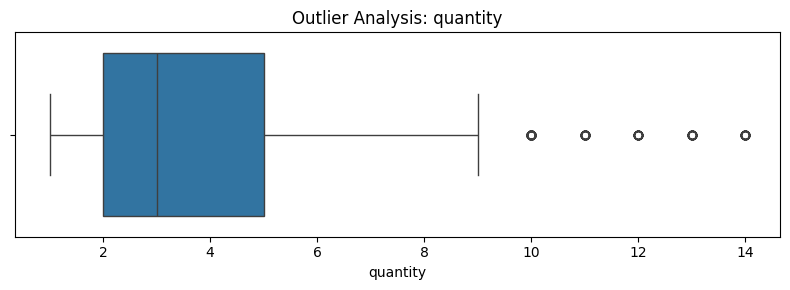

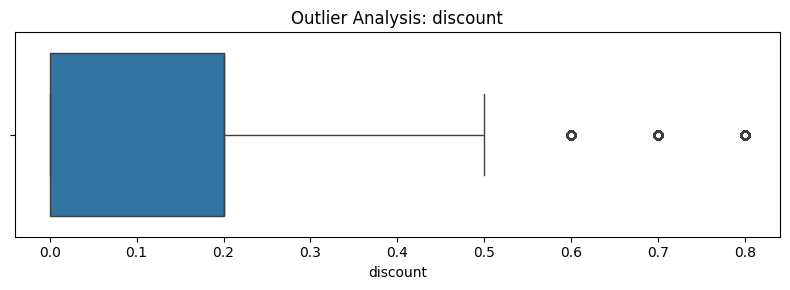

In [9]:
for column in outlier_columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Outlier Analysis: {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

,region,total_sales
3,West,725457.8245
1,East,678781.2400
0,Central,501239.8908
2,South,391721.9050


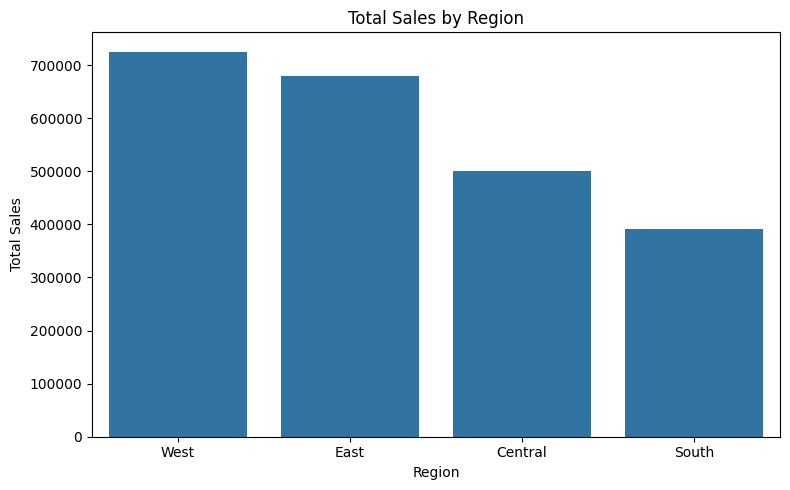

In [10]:
region_sales = (
    df.groupby("region", as_index=False)
    .agg(total_sales=("sales", "sum"))
    .sort_values("total_sales", ascending=False)
)

display(region_sales)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="region",
    y="total_sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

,category,total_profit
2,Technology,145454.9481
1,Office Supplies,122490.8008
0,Furniture,18451.2728


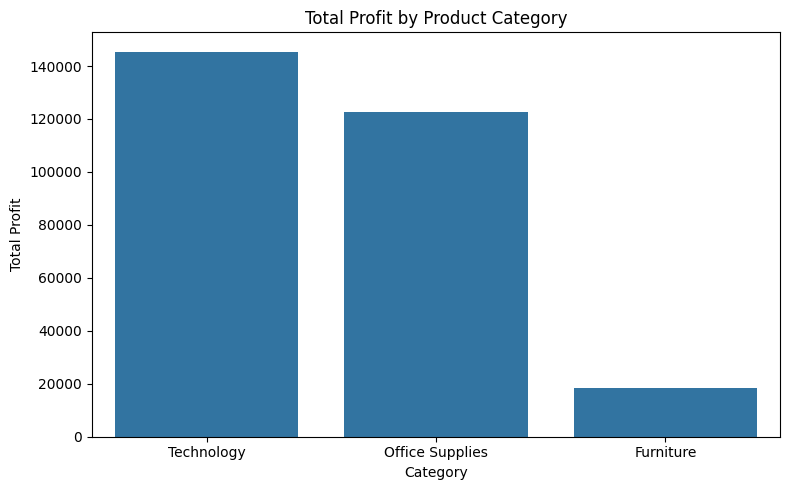

In [11]:
category_profit = (
    df.groupby("category", as_index=False)
    .agg(total_profit=("profit", "sum"))
    .sort_values("total_profit", ascending=False)
)

display(category_profit)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_profit,
    x="category",
    y="total_profit"
)

plt.title("Total Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()

In [20]:
subcategory_profit = (
    df.groupby("sub-category", as_index=False)
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum")
    )
    .sort_values("total_profit")
)

display(subcategory_profit)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=subcategory_profit,
    x="total_profit",
    y="sub_category"
)

plt.axvline(0, linestyle="--")

plt.title("Profit by Product Subcategory")
plt.xlabel("Total Profit")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

,sub-category,total_sales,total_profit
16,Tables,206965.5320,-17725.4811
4,Bookcases,114879.9963,-3472.5560
15,Supplies,46673.5380,-1189.0995
8,Fasteners,3024.2800,949.5182
11,Machines,189238.6310,3384.7569
10,Labels,12486.3120,5546.2540
2,Art,27118.7920,6527.7870
7,Envelopes,16476.4020,6964.1767
9,Furnishings,91705.1640,13059.1436
1,Appliances,107532.1610,18138.0054


ValueError: Could not interpret value `sub_category` for `y`. An entry with this name does not appear in `data`.

<Figure size 1000x700 with 0 Axes>

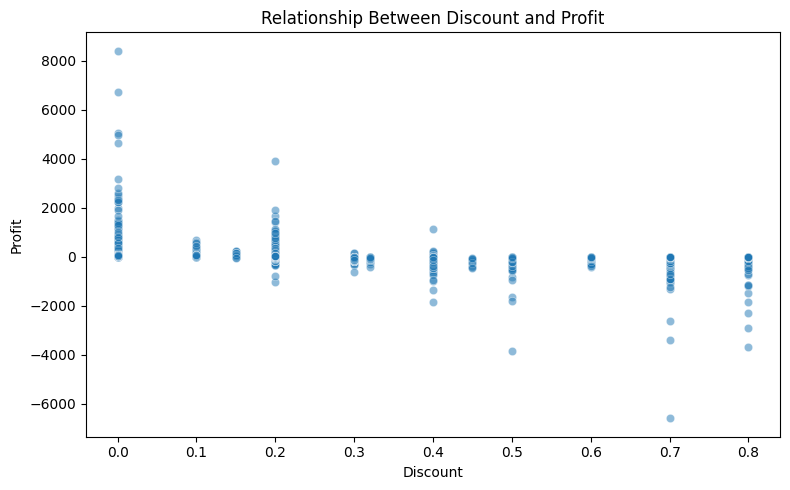

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="discount",
    y="profit",
    alpha=0.5
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show(
    
)

In [15]:
discount_analysis = (
    df.groupby("discount", as_index=False)
    .agg(
        average_profit=("profit", "mean"),
        total_sales=("sales", "sum"),
        transaction_count=("profit", "size")
    )
    .sort_values("discount")
)

display(discount_analysis)

,discount,average_profit,total_sales,transaction_count
0,0.00,66.900292,1.087908e+06,4798
1,0.10,96.055074,5.436935e+04,94
2,0.15,27.288298,2.755852e+04,52
3,0.20,24.702572,7.645944e+05,3657
4,0.30,-45.679636,1.032267e+05,227
5,0.32,-88.560656,1.449346e+04,27
6,0.40,-111.927429,1.164178e+05,206
7,0.45,-226.646464,5.484974e+03,11
8,0.50,-310.703456,5.891854e+04,66
9,0.60,-43.077212,6.644700e+03,138


,order_month,total_sales
0,2014-01-01,14236.8950
1,2014-02-01,4519.8920
2,2014-03-01,55691.0090
3,2014-04-01,28295.3450
4,2014-05-01,23648.2870
5,2014-06-01,34595.1276
6,2014-07-01,33946.3930
7,2014-08-01,27909.4685
8,2014-09-01,81777.3508
9,2014-10-01,31453.3930


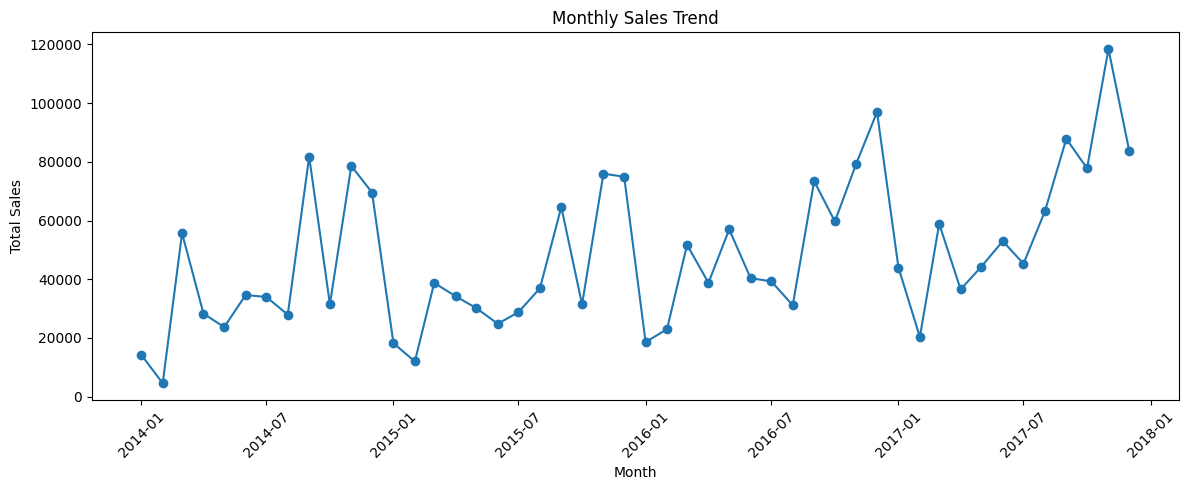

In [16]:
df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

monthly_sales = (
    df.groupby("order_month", as_index=False)
    .agg(total_sales=("sales", "sum"))
    .sort_values("order_month")
)

display(monthly_sales)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["order_month"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
## Conclusion

This Exploratory Data Analysis examined the Sample Superstore Sales
dataset using data profiling, summary statistics, numerical
distribution plots, correlation analysis, outlier detection, and
business-focused visualisations.

The analysis investigated regional sales, category-level profitability,
subcategory losses, discount-profit relationships, and monthly sales
trends.

The findings can support decisions related to inventory planning,
product strategy, pricing, discount management, and regional sales
performance.

All business conclusions should be based on the computed results
and visual evidence produced in this notebook.